## 1. Load ringgit data
Daily exchange rates from Bank Negara Malaysia (data.gov.my)

In [13]:
import pandas as pd

URL = 'https://storage.data.gov.my/finsector/exr/daily_1200.parquet'
fx = pd.read_parquet(URL)

print(fx.shape)
print(fx.columns.tolist())
print(fx['rate_type'].unique())
fx.head()

(18838, 29)
['date', 'rate_type', 'USD', 'EUR', 'JPY', 'GBP', 'SGD', 'AUD', 'CAD', 'CNY', 'CHF', 'THB', 'IDR', 'VND', 'KHR', 'MMK', 'PHP', 'BND', 'KRW', 'HKD', 'TWD', 'INR', 'PKR', 'NPR', 'SAR', 'AED', 'EGP', 'NZD', 'XDR']
<ArrowStringArray>
['middle', 'buying', 'selling']
Length: 3, dtype: str


,date,rate_type,USD,EUR,JPY,GBP,SGD,AUD,CAD,CNY,...,HKD,TWD,INR,PKR,NPR,SAR,AED,EGP,NZD,XDR
0,1997-01-02,middle,2.5265,NaN,0.021792,4.3188,1.8059,NaN,NaN,NaN,...,0.3267,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.6385
1,1997-01-03,middle,2.5245,NaN,0.021867,4.2765,1.8039,NaN,NaN,NaN,...,0.3264,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.6318
2,1997-01-06,middle,2.5205,NaN,0.021607,4.2637,1.7946,NaN,NaN,NaN,...,0.3258,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.6109
3,1997-01-07,middle,2.5000,NaN,0.021710,4.2338,1.7800,NaN,NaN,NaN,...,0.3231,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.5874
4,1997-01-08,middle,2.4913,NaN,0.021592,4.2238,1.7757,NaN,NaN,NaN,...,0.3220,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.5662


In [14]:
fx.to_parquet('fx_raw.parquet')
print('Saved!')

Saved!


## 2. Clean ringgit data
Keep only the USD middle rate from 22 July 2005 (after the ringgit peg ended)

In [15]:
usd = fx[fx['rate_type'] == 'middle'][['date', 'USD']].copy() 
usd['date'] = pd.to_datetime(usd['date'])
usd = usd.set_index('date').sort_index()

usd = usd[usd.index >= '2005-07-22']

print(usd.shape)
print(usd.isna().sum())
print(usd.index.min(), 'to', usd.index.max())
usd.head()

(5222, 1)
USD    0
dtype: int64
2005-07-22 00:00:00 to 2026-10-23 00:00:00


,USD
date,
2005-07-22,3.7825
2005-07-25,3.7605
2005-07-26,3.7510
2005-07-27,3.7505
2005-07-28,3.7495


## 3. First look at the ringgit

count    5222.000000
mean        3.827605
std         0.508276
min         2.938500
25%         3.332625
50%         3.944500
75%         4.218000
max         4.793500
Name: USD, dtype: float64


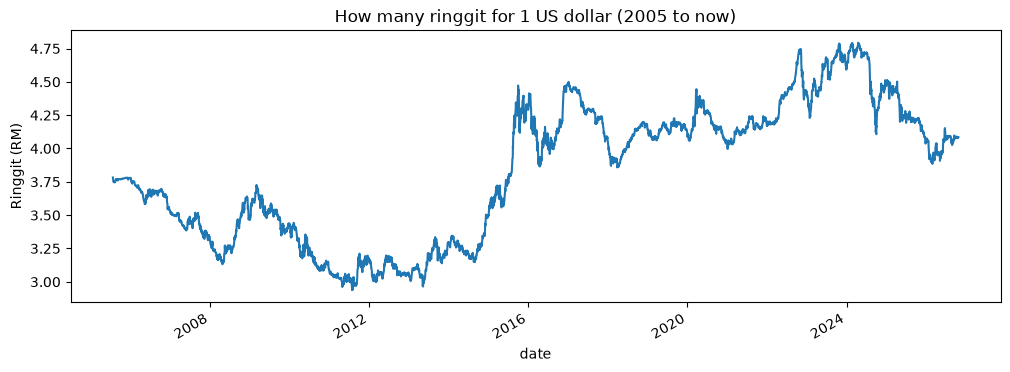

In [16]:
import matplotlib.pyplot as plt

print(usd['USD'].describe())

usd['USD'].plot(figsize=(12, 4))
plt.title('How many ringgit for 1 US dollar (2005 to now)')
plt.ylabel('Ringgit (RM)')
plt.show()

## 4. Load oil price data
Daily Brent crude oil prices from FRED, in USD per barrel

In [17]:
OIL_URL = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=DCOILBRENTEU'
oil = pd.read_csv(OIL_URL)

oil.columns = ['date', 'Brent']
oil['date'] = pd.to_datetime(oil['date'])
oil['Brent'] = pd.to_numeric(oil['Brent'], errors='coerce')
oil = oil.set_index('date').sort_index()

oil.to_csv('oil_raw.csv')

print(oil.shape)
print(oil.isna().sum())
print(oil.index.min(), 'to', oil.index.max())
oil.tail()

(10285, 1)
Brent    1173
dtype: int64
1987-05-20 00:00:00 to 2026-10-20 00:00:00


,Brent
date,
2026-10-14,126.55
2026-10-15,126.35
2026-10-16,119.33
2026-10-19,118.82
2026-10-20,115.22


## 5. Check empty days in oil data
Daily Brent crude oil prices from FRED, in USD per barrel

In [18]:
empty_days = oil[oil['Brent'].isna()]
print(empty_days.index.day_name().value_counts())

date
Monday       321
Friday       243
Tuesday      220
Wednesday    200
Thursday     189
Name: count, dtype: int64


## 6. Join ringgit and oil data

In [19]:
df = usd.join(oil, how='inner').dropna()

print(df.shape)
print(df.isna().sum())
print(df.index.min(), 'to', df.index.max())
df.head()

(5066, 2)
USD      0
Brent    0
dtype: int64
2005-07-22 00:00:00 to 2026-10-20 00:00:00


,USD,Brent
date,,
2005-07-22,3.7825,56.98
2005-07-25,3.7605,57.51
2005-07-26,3.7510,58.58
2005-07-27,3.7505,58.34
2005-07-28,3.7495,58.28


In [20]:
df = df.rename(columns={'USD': 'MYR_per_USD', 'Brent': 'Brent_USD'})
df.head()

,MYR_per_USD,Brent_USD
date,,
2005-07-22,3.7825,56.98
2005-07-25,3.7605,57.51
2005-07-26,3.7510,58.58
2005-07-27,3.7505,58.34
2005-07-28,3.7495,58.28


## 7. Ringgit vs oil price over time
Blue line = ringgit per 1 USD (left axis), orange line = Brent oil price (right axis)

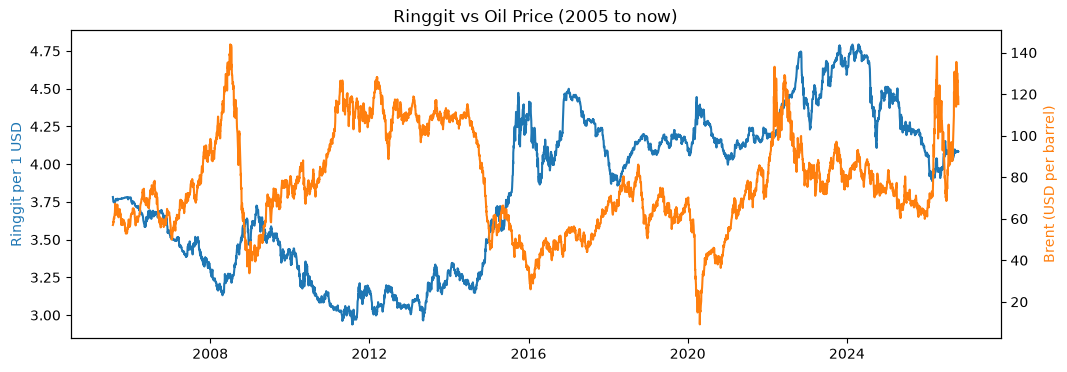

In [21]:
fig, ax1 = plt.subplots(figsize=(12, 4))

ax1.plot(df.index, df['MYR_per_USD'], color='tab:blue')
ax1.set_ylabel('Ringgit per 1 USD', color='tab:blue')

ax2 = ax1.twinx()
ax2.plot(df.index, df['Brent_USD'], color='tab:orange')
ax2.set_ylabel('Brent (USD per barrel)', color='tab:orange')

plt.title('Ringgit vs Oil Price (2005 to now)')
plt.show()

## 8. How strong is the link? (correlation)
Correlation between the ringgit and oil price, for all years and before vs after 2022

In [22]:
before = df[df.index < '2022-01-01']
after = df[df.index >= '2022-01-01']

all_corr = df['MYR_per_USD'].corr(df['Brent_USD'])
before_corr = before['MYR_per_USD'].corr(before['Brent_USD'])
after_corr = after['MYR_per_USD'].corr(after['Brent_USD'])

print('All years (2005–now):', round(all_corr, 2))
print('Before 2022:', round(before_corr, 2))
print('2022–now:', round(after_corr, 2))

All years (2005–now): -0.47
Before 2022: -0.79
2022–now: -0.08


## 9. Do monthly changes move together?
A stronger test: correlation of monthly % changes in the ringgit and oil price

In [23]:
monthly = df.resample('ME').last()
changes = monthly.pct_change().dropna()

before_ch = changes[changes.index < '2022-01-01']
after_ch = changes[changes.index >= '2022-01-01']

print('Months:', len(changes))
print('All years:', round(changes['MYR_per_USD'].corr(changes['Brent_USD']), 2))
print('Before 2022:', round(before_ch['MYR_per_USD'].corr(before_ch['Brent_USD']), 2))
print('2022–now:', round(after_ch['MYR_per_USD'].corr(after_ch['Brent_USD']), 2))

Months: 255
All years: -0.1
Before 2022: -0.22
2022–now: 0.2


## 10. Does the ringgit react later? (lag test)
Correlation between ringgit changes and oil changes from 0–3 months earlier (before 2022)

In [24]:
for lag in [0, 1, 2, 3]:
    oil_earlier = before_ch['Brent_USD'].shift(lag)
    corr = before_ch['MYR_per_USD'].corr(oil_earlier)
    print(f'Oil {lag} month(s) earlier:', round(corr, 2))

Oil 0 month(s) earlier: -0.22
Oil 1 month(s) earlier: -0.07
Oil 2 month(s) earlier: -0.08
Oil 3 month(s) earlier: -0.0
